# 04 — Figures

**Project:** Do U.S. climate change concerns move European green-minus-brown returns?
**Author:** Rafael Machado Cerqueira — Advanced Data Analytics, HEC Lausanne, Autumn 2026

**Input:** `data/processed/` (02_clean) and `results/` (03_model). **Output:** every figure of the paper, in `figures/`, as PDF (for LaTeX) and PNG.

| Figure | Content | Paper section |
|---|---|---|
| 1 | The MCCC index over time, with its largest surprises | Data |
| 2 | Frozen prices of the small green stocks (liquidity rule) | Data |
| 3 | Cumulative returns of the green and brown portfolios, and the spreads | Data |
| 4 | Shock coefficients with 95% confidence intervals | Results |
| 5 | Leave-one-out | Results / robustness |
| 6 | Largest daily moves of the European spread | Discussion |
| 7 | Shape learned by the random forest | Results / non-linear model |
| 8 | Out-of-sample R² by year | Results / non-linear model |

No number is typed by hand: every figure is drawn from the saved files, so re-running 02 and 03 updates it.

*Code drafted with Claude (Anthropic) and reviewed by the author — declared in the paper's appendix.*

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
PROC, RES, FIG = ROOT / "data" / "processed", ROOT / "results", ROOT / "figures"
FIG.mkdir(exist_ok=True)

# One style for every figure: readable when printed at column width in the SIAM template
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})
GREEN, BROWN, NEUTRAL, US_COL = "#2e7d32", "#8d6e63", "#1F3B57", "#c62828"
WIDE, TALL = (7.0, 3.2), (7.0, 4.2)
N_LABELS = 5          # number of dates labelled on figures 1 and 6

def save(fig, name, layout=True):
    if layout:
        fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    plt.show()
    print("Saved figures/" + name + ".pdf and .png")

def read_table(name, n_index=1):
    """Read a results table; returns None (with a message) if 03_model has not produced it."""
    path = RES / name
    if not path.exists():
        print(f"Missing {name}: run 03_model first. Skipped.")
        return None
    return pd.read_csv(path, index_col=list(range(n_index)))

read = lambda name: pd.read_csv(PROC / name, index_col=0, parse_dates=True)
panel_eu, panel_us = read("panel_eu.csv"), read("panel_us.csv")
mccc = read("mccc_eu_calendar_full.csv")
shocks = read("concern_shocks.csv")
print("Figures go to:", FIG)

Figures go to: /Users/RafaelMachadoCerqueira/Desktop/Data/climate-concerns-green-brown/figures


## Figure 1 — The MCCC index and its largest surprises

The daily index (light) and its 30-trading-day average (dark), 2003–2025. The vertical lines mark the largest positive concern shocks of the main definition (03_model, section 2b): check in the press archive what happened on those dates before describing them in the paper.

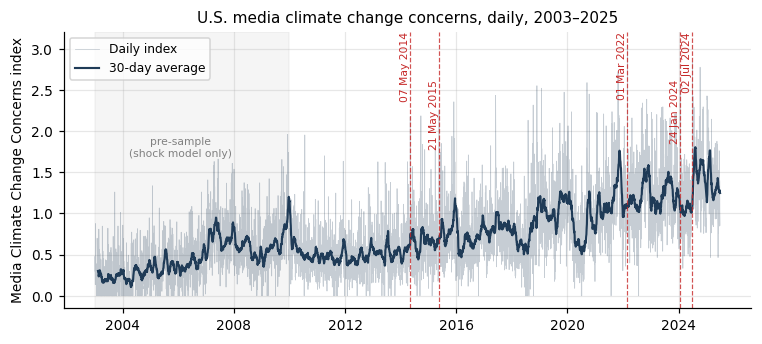

Saved figures/fig1_mccc_index.pdf and .png


,shock (sd)
date,
2022-03-01,5.67
2015-05-21,4.65
2024-07-02,4.62
2014-05-07,4.59
2024-01-24,4.57


In [2]:
level = mccc["mccc_Aggregate"]
top = shocks["eu"].nlargest(N_LABELS)

fig, ax = plt.subplots(figsize=WIDE)
ax.plot(level.index, level, color=NEUTRAL, alpha=0.25, lw=0.5, label="Daily index")
ax.plot(level.index, level.rolling(30).mean(), color=NEUTRAL, lw=1.4, label="30-day average")
ymax = ax.get_ylim()[1]
for k, d in enumerate(sorted(top.index)):
    ax.axvline(d, color=US_COL, lw=0.8, ls="--", alpha=0.8)
    ax.text(d, ymax * (1 - 0.18 * (k % 2)), d.strftime("%d %b %Y"), rotation=90, va="top", ha="right",
            fontsize=7, color=US_COL)   # alternate heights so close dates do not overlap
ax.axvspan(level.index.min(), pd.Timestamp("2009-12-31"), color="grey", alpha=0.08)
ax.text(0.17, 0.55, "pre-sample\n(shock model only)", transform=ax.transAxes, ha="center",
        fontsize=7, color="grey")
ax.set_ylabel("Media Climate Change Concerns index")
ax.set_title("U.S. media climate change concerns, daily, 2003–2025")
ax.legend(loc="upper left")
save(fig, "fig1_mccc_index")
top.round(2).rename("shock (sd)").to_frame()

## Figure 2 — Frozen prices and the liquidity rule

Share of days with exactly zero return, by year, for the stocks whose entry the rule delays (02_clean, section 5). A stock enters the portfolio from the year after which this share stays below the threshold.

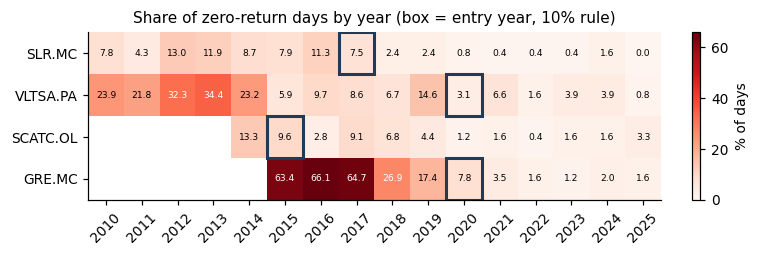

Saved figures/fig2_liquidity.pdf and .png


In [3]:
zero = pd.read_csv(PROC / "zero_return_share_by_year.csv", index_col=0)
entry = pd.read_csv(PROC / "liquidity_entry.csv", index_col=0)
entry_col = [c for c in entry.columns if c.startswith("entry_year_")][0]   # main threshold (first column)
threshold = int(entry_col.split("_")[-1].replace("pct", "")) / 100
first_year = pd.to_datetime(entry["first_price"]).dt.year
delayed = entry.index[entry[entry_col].astype(float) > first_year].tolist()

z = zero[delayed].T * 100
fig, ax = plt.subplots(figsize=(7.0, max(1.8, 0.6 + 0.45 * len(delayed))))
im = ax.imshow(z.values, aspect="auto", cmap="Reds", vmin=0, vmax=max(40, np.nanmax(z.values)))
years = [int(c) for c in z.columns]
ax.set_xticks(range(z.shape[1]), years, rotation=45)
ax.set_yticks(range(len(delayed)), delayed)
ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = z.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 25 else "black")
    ey = entry.loc[delayed[i], entry_col]
    if pd.notna(ey) and int(float(ey)) in years:
        ax.add_patch(plt.Rectangle((years.index(int(float(ey))) - 0.5, i - 0.5), 1, 1,
                                   fill=False, ec=NEUTRAL, lw=2))
fig.colorbar(im, ax=ax, label="% of days", fraction=0.03)
ax.set_title(f"Share of zero-return days by year (box = entry year, {threshold:.0%} rule)")
save(fig, "fig2_liquidity")

## Figure 3 — Cumulative returns

(a) Value of 1 EUR invested in the equal-weighted green and brown European portfolios. (b) Cumulative sum of the daily green-minus-brown spread, Europe (EUR) and U.S. (ICLN − XLE, USD).

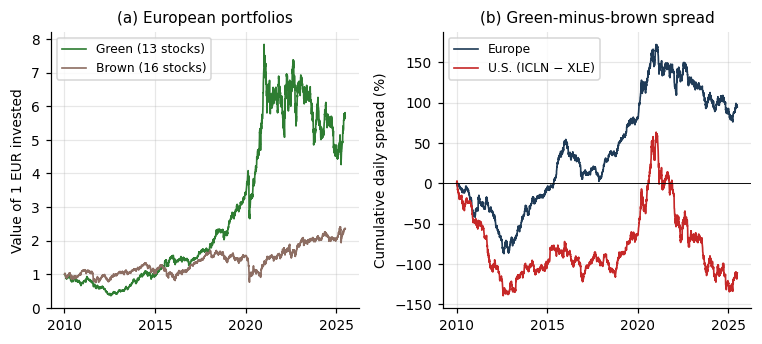

Saved figures/fig3_cumulative_returns.pdf and .png


In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=WIDE)
for col, colour, label in [("green", GREEN, "Green (13 stocks)"), ("brown", BROWN, "Brown (16 stocks)")]:
    a.plot((1 + panel_eu[col].fillna(0)).cumprod(), color=colour, lw=1.1, label=label)
a.set_title("(a) European portfolios")
a.set_ylabel("Value of 1 EUR invested")
a.legend()
b.plot(panel_eu["spread"].fillna(0).cumsum() * 100, color=NEUTRAL, lw=1.1, label="Europe")
b.plot(panel_us["spread"].fillna(0).cumsum() * 100, color=US_COL, lw=1.1, label="U.S. (ICLN − XLE)")
b.axhline(0, color="black", lw=0.6)
b.set_title("(b) Green-minus-brown spread")
b.set_ylabel("Cumulative daily spread (%)")
b.legend()
for ax in (a, b):
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
save(fig, "fig3_cumulative_returns")

## Figure 4 — Effect of a concern shock, with 95% confidence intervals

Each line is one regression from 03_model; the point is the coefficient on the same-day (●) or previous-day (○) shock, in basis points of daily spread per one-standard-deviation shock. The interval is ±1.96 Newey-West standard errors (standard error = coefficient / t-statistic). An interval crossing zero means no detectable effect.

(a) Europe: main model and robustness checks. (b) Other horizons and the U.S. benchmark (cumulative and weekly coefficients are per week, so their scale is larger).

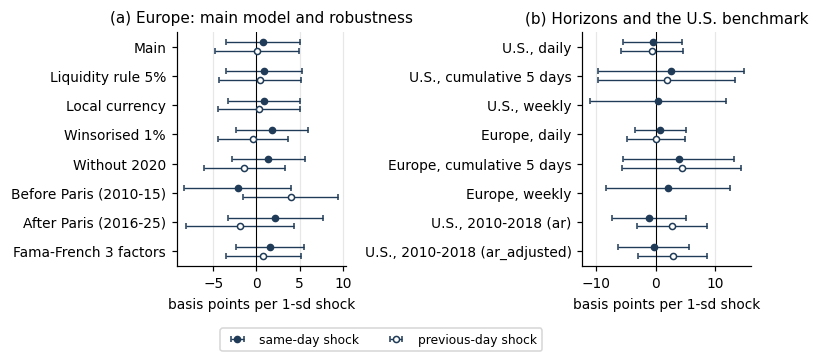

Saved figures/fig4_coefficients.pdf and .png


In [5]:
def interval(df, var):
    coef = df[f"{var}_bps"]
    se = (coef / df[f"{var}_t"]).abs().replace([np.inf], np.nan)
    return coef, 1.96 * se

def coef_panel(ax, df, labels, title):
    y = np.arange(len(df))[::-1]
    for var, marker, offset in [("shock_t", "o", 0.15), ("shock_lag1", "o", -0.15)]:
        if f"{var}_bps" not in df:
            continue
        coef, ci = interval(df, var)
        ok = coef.notna().values
        ax.errorbar(coef[ok], y[ok] + offset, xerr=ci[ok], fmt=marker, ms=4, capsize=2, lw=0.9,
                    color=NEUTRAL, mfc=NEUTRAL if var == "shock_t" else "white",
                    label="same-day shock" if var == "shock_t" else "previous-day shock")
    ax.axvline(0, color="black", lw=0.7)
    ax.set_yticks(y, labels)
    ax.set_xlabel("basis points per 1-sd shock")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0)

robust = read_table("robustness.csv")
horizons = read_table("longer_horizons.csv", 2)
ardia = read_table("us_ardia_period.csv", 2)

panels = []
if robust is not None:
    panels.append((robust, list(robust.index), "(a) Europe: main model and robustness"))
if horizons is not None:
    rows = [horizons]
    labels = [f"{m}, {h.replace(' (section 4)', '')}" for m, h in horizons.index]
    if ardia is not None:
        a3 = ardia[ardia.index.get_level_values(1).str.contains("(3)", regex=False)]
        rows.append(a3)
        labels += [f"U.S., 2010-2018 ({d})" for d, _ in a3.index]
    panels.append((pd.concat(rows), labels, "(b) Horizons and the U.S. benchmark"))

fig, axes = plt.subplots(1, len(panels), figsize=(7.0, 0.6 + 0.32 * max(len(p[0]) for p in panels)))
axes = np.atleast_1d(axes)
for ax, (df, labels, title) in zip(axes, panels):
    coef_panel(ax, df, labels, title)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "fig4_coefficients", layout=False)

## Figure 5 — Leave-one-out

The main European model re-estimated 29 times, each time without one stock. The dashed line is the estimate with all stocks. If no single stock drives the result, the points stay close to it.

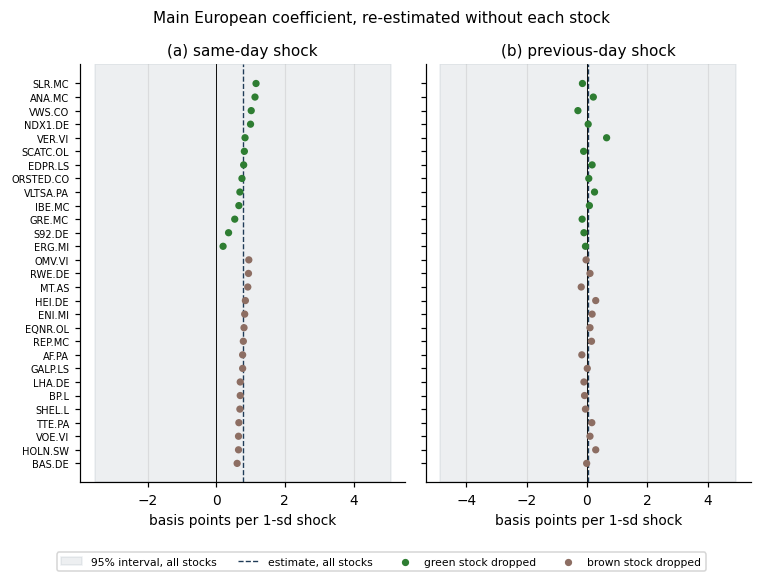

Saved figures/fig5_leave_one_out.pdf and .png


In [6]:
loo = read_table("leave_one_out.csv")
main = robust.loc["Main"] if robust is not None else None
if loo is not None:
    fig, axes = plt.subplots(1, 2, figsize=WIDE, sharey=True)
    loo_sorted = loo.sort_values(["side", "shock_t_bps"])
    y = np.arange(len(loo_sorted))
    colours = [GREEN if s == "green" else BROWN for s in loo_sorted["side"]]
    for ax, var, title in [(axes[0], "shock_t", "same-day shock"), (axes[1], "shock_lag1", "previous-day shock")]:
        ax.scatter(loo_sorted[f"{var}_bps"], y, c=colours, s=14, zorder=3)
        if main is not None:
            se = abs(main[f"{var}_bps"] / main[f"{var}_t"])
            ax.axvspan(main[f"{var}_bps"] - 1.96 * se, main[f"{var}_bps"] + 1.96 * se, color=NEUTRAL,
                       alpha=0.08, label="95% interval, all stocks")
            ax.axvline(main[f"{var}_bps"], color=NEUTRAL, ls="--", lw=0.9, label="estimate, all stocks")
        ax.axvline(0, color="black", lw=0.6)
        ax.set_title(f"({'a' if var == 'shock_t' else 'b'}) {title}")
        ax.set_xlabel("basis points per 1-sd shock")
        ax.grid(axis="y", alpha=0)
    axes[0].set_yticks(y, loo_sorted.index, fontsize=6.5)
    axes[0].scatter([], [], c=GREEN, s=14, label="green stock dropped")
    axes[0].scatter([], [], c=BROWN, s=14, label="brown stock dropped")
    handles, labels_ = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="lower center", ncol=4, fontsize=7, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle("Main European coefficient, re-estimated without each stock", fontsize=10)
    fig.set_size_inches(7.0, 5.2)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    save(fig, "fig5_leave_one_out", layout=False)

## Figure 6 — What moves the European spread

The daily green-minus-brown spread, with the largest moves labelled by date. These days come from 03_model, section 5 (largest residuals): check what happened on each date before describing it in the paper.

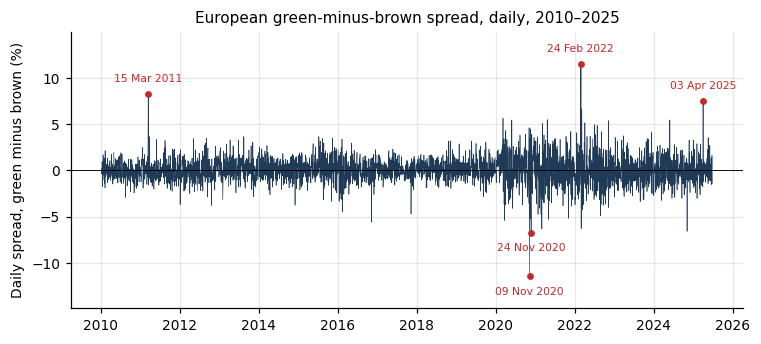

Saved figures/fig6_spread_largest_moves.pdf and .png


,spread_%,Brent_%,market_%
2022-02-24,11.52,2.01,-3.56
2020-11-09,-11.48,7.48,3.19
2011-03-15,8.20,-1.63,-2.23
2025-04-03,7.47,-6.12,-0.89
2020-11-24,-6.73,3.62,1.26


In [7]:
s = panel_eu["spread"] * 100
# The largest moves, keeping one date per episode (moves less than 10 days apart count as one episode)
big = []
for d in s.abs().sort_values(ascending=False).index:
    if all(abs((d - b).days) > 10 for b in big):
        big.append(d)
    if len(big) == N_LABELS:
        break
big = pd.DatetimeIndex(big)

fig, ax = plt.subplots(figsize=WIDE)
ax.plot(s.index, s, color=NEUTRAL, lw=0.4)
for d in big:
    ax.annotate(d.strftime("%d %b %Y"), (d, s[d]), xytext=(0, 8 if s[d] > 0 else -12),
                textcoords="offset points", ha="center", fontsize=7, color=US_COL)
    ax.scatter([d], [s[d]], color=US_COL, s=12, zorder=3)
ax.axhline(0, color="black", lw=0.6)
ax.margins(y=0.15)
ax.set_ylabel("Daily spread, green minus brown (%)")
ax.set_title("European green-minus-brown spread, daily, 2010–2025")
save(fig, "fig6_spread_largest_moves")
pd.DataFrame({"spread_%": s[big].round(2), "Brent_%": (panel_eu.loc[big, "brent_ret"] * 100).round(2),
              "market_%": (panel_eu.loc[big, "ff_mkt_rf"] * 100).round(2)})

## Figure 7 — The shape learned by the random forest

Partial dependence: the forest's average predicted spread as one shock varies (scikit-learn evaluates it between the 5th and 95th percentiles of each shock, so the far tail above about 2 sd is not drawn), all other inputs held at their observed values (03_model, section 7). A flat line means the shock is not used; a jump only at large values would match the exploratory large-shock result (section 6c). The rug marks show where the data are: few days lie in the right tail.

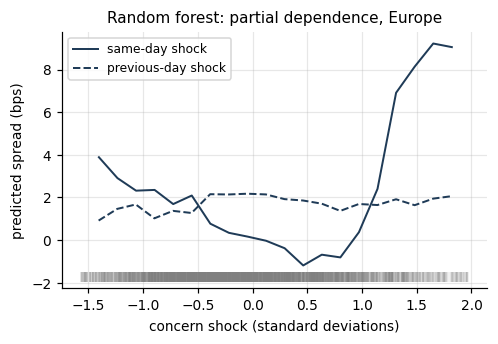

Saved figures/fig7_rf_partial_dependence.pdf and .png


In [8]:
pdp = read_table("rf_partial_dependence.csv")
if pdp is not None:
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    for var, style, label in [("shock_t", "-", "same-day shock"), ("shock_lag1", "--", "previous-day shock")]:
        d = pdp[pdp.index == var] if "variable" not in pdp.columns else pdp[pdp["variable"] == var]
        ax.plot(d["shock_value"], d["predicted_spread_bps"], style, color=NEUTRAL, lw=1.3, label=label)
    rug = shocks["eu"].dropna()
    rug = rug[(rug > ax.get_xlim()[0]) & (rug < ax.get_xlim()[1])]
    ax.plot(rug, np.full(len(rug), ax.get_ylim()[0]), "|", color="grey", alpha=0.15, ms=6)
    ax.set_xlabel("concern shock (standard deviations)")
    ax.set_ylabel("predicted spread (bps)")
    ax.set_title("Random forest: partial dependence, Europe")
    ax.legend()
    save(fig, "fig7_rf_partial_dependence")

## Figure 8 — Out-of-sample R² by year

Each model is trained on all earlier years and tested on the year shown (03_model, section 7). Positive bars beat the historical mean. If the shocks carried information, the bars with shocks would be higher than the controls-only bars.

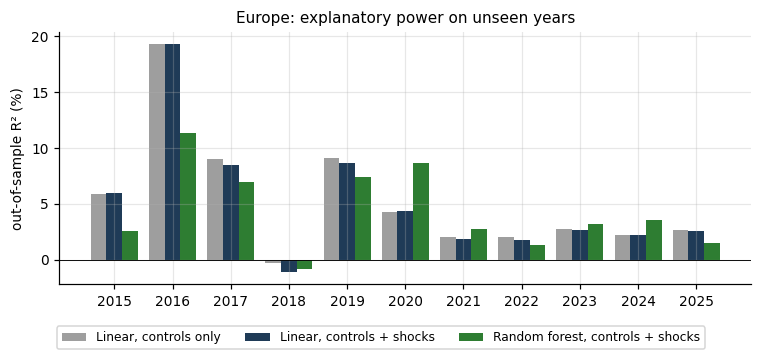

Saved figures/fig8_oos_by_year.pdf and .png


In [9]:
oos = read_table("oos_by_year.csv")
if oos is not None:
    models = [("linear_controls", "Linear, controls only", "#9e9e9e"),
              ("linear_full", "Linear, controls + shocks", NEUTRAL),
              ("random_forest", "Random forest, controls + shocks", GREEN)]
    x, w = np.arange(len(oos)), 0.27
    fig, ax = plt.subplots(figsize=WIDE)
    for k, (col, label, colour) in enumerate(models):
        ax.bar(x + (k - 1) * w, oos[col], width=w, color=colour, label=label)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x, oos.index)
    ax.set_ylabel("out-of-sample R² (%)")
    ax.set_title("Europe: explanatory power on unseen years")
    handles, labels_ = ax.get_legend_handles_labels()
    fig.legend(handles, labels_, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    save(fig, "fig8_oos_by_year", layout=False)

## Check

In [10]:
print(sorted(p.name for p in FIG.iterdir()))

['fig1_mccc_index.pdf', 'fig1_mccc_index.png', 'fig2_liquidity.pdf', 'fig2_liquidity.png', 'fig3_cumulative_returns.pdf', 'fig3_cumulative_returns.png', 'fig4_coefficients.pdf', 'fig4_coefficients.png', 'fig5_leave_one_out.pdf', 'fig5_leave_one_out.png', 'fig6_spread_largest_moves.pdf', 'fig6_spread_largest_moves.png', 'fig7_rf_partial_dependence.pdf', 'fig7_rf_partial_dependence.png', 'fig8_oos_by_year.pdf', 'fig8_oos_by_year.png']
